# Models

In [2]:
import torch
import random

if torch.backends.mps.is_available():
    torch.set_default_device("mps")
    print("MPS device found!")


SEED = random.SystemRandom().randint(0, 2**32 - 1)
torch.manual_seed(SEED)
print(f"Random seed: {SEED}")

MPS device found!
Random seed: 480963469


## Linear Regression (Raw)

Epoch 00: Loss=9.0343, W=-0.164, b=-0.712
Epoch 10: Loss=6.3488, W=0.248, b=-0.412
Epoch 20: Loss=4.5558, W=0.585, b=-0.168
Epoch 30: Loss=3.3586, W=0.862, b=0.030
Epoch 40: Loss=2.5593, W=1.088, b=0.191
Epoch 50: Loss=2.0256, W=1.273, b=0.323
Epoch 60: Loss=1.6692, W=1.425, b=0.429
Epoch 70: Loss=1.4312, W=1.550, b=0.516
Epoch 80: Loss=1.2723, W=1.652, b=0.587
Epoch 90: Loss=1.1661, W=1.735, b=0.644


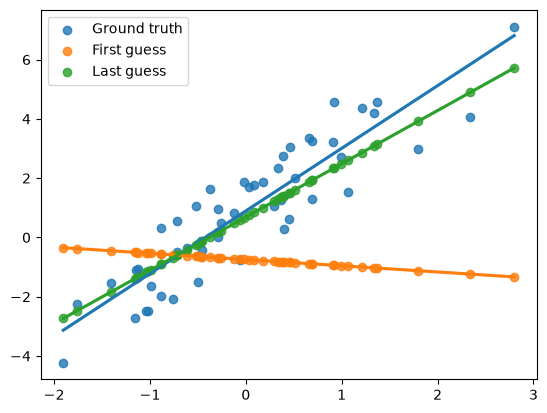

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
from torch import Tensor
from numpy.typing import NDArray
from matplotlib.pyplot import Axes

def to_numpy(tensor: Tensor) -> NDArray:
    return tensor.detach().cpu().numpy().squeeze()

fig, ax = plt.subplots()

def addToPlot(X: Tensor, Y: Tensor, label: str):
    sns.regplot(
    x=to_numpy(X),
    y=to_numpy(Y),
    ax=ax,
    ci=None,
    label=label
)

N = 50
D_x = 1
D_y = 1
X = torch.randn(N, D_x)

# True data generator
true_W = torch.tensor([[2.0]])
true_b = torch.tensor([[1]])
y_true = X @ true_W + true_b + 1.0*torch.randn(N, D_y)

# Model
W, b = torch.randn(D_x, D_y, requires_grad=True), torch.randn(1, D_y, requires_grad=True)
learning_rate, epochs = 0.01, 100

addToPlot(X, y_true, "Ground truth")

# Forward pass
y_hat = X@W+b

addToPlot(X, y_hat, "First guess")

for epoch in range(epochs):

    loss = torch.mean((y_hat - y_true) ** 2)

    # Backwards pass: compute gradients
    loss.backward()

    # Update params
    with torch.no_grad():
        W -= learning_rate * W.grad; b-= learning_rate * b.grad

    # Zero gradients
    W.grad.zero_(); b.grad.zero_()

    if epoch % 10 == 0:
        print(f"Epoch {epoch:02d}: Loss={loss.item():.4f}, W={W.item():.3f}, b={b.item():.3f}")

    # Forward pass
    y_hat = X@W+b



addToPlot(X, y_hat, "Last guess")

ax.legend()
plt.show()

# Regression (torch.nn)